# Questão 1 – Domínio, imagem e curvas de nível

Construa modelos computacionais para as três funções:

$$f_1(x,y) = \sqrt{9 - x^2 - y^2} \qquad f_2(x,y) = \ln(4 - x^2 - y^2) \qquad f_3(x,y) = \frac{1}{x^2 + y^2 - 1}$$

A primeira célula de código abaixo carrega as bibliotecas e as funções auxiliares usadas em todos os itens. Rode-a antes das demais.

In [1]:
# 💻 Configuração: bibliotecas, grade e funções auxiliares
import numpy as np
import matplotlib.pyplot as plt

# Grade no plano xy (801 pontos inclui exatamente a origem)
x = np.linspace(-4, 4, 801)
y = np.linspace(-4, 4, 801)
X, Y = np.meshgrid(x, y)


def avaliar(f):
    """Avalia f na grade. Fora do domínio o NumPy devolve nan/inf (sem avisos)."""
    with np.errstate(all='ignore'):
        return f(X, Y)


def plot_dominio(ax, mascara, fronteira, incluida, titulo):
    """Pinta onde mascara é True e desenha a curva fronteira == 0.
    incluida=True -> linha cheia | incluida=False -> tracejada."""
    ax.contourf(X, Y, mascara.astype(int), levels=[0.5, 1.5], colors=['#4c9be8'], alpha=0.4)
    ax.contour(X, Y, fronteira, levels=[0], colors='k',
               linestyles='solid' if incluida else 'dashed', linewidths=1.8)
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.set_aspect('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(titulo)


def conferir_dominio(Z, mascara):
    """Compara a máscara (análise na mão) com os pontos onde f deu um número finito."""
    auto = np.isfinite(Z)
    diferentes = np.sum(auto != mascara)
    print(f"Pontos em que máscara e isfinite discordam: {diferentes} de {mascara.size}")
    print("(alguns poucos pontos exatamente na fronteira podem divergir por arredondamento)")

---
## Item 1 – Domínio e fronteira

> **Enunciado:** Determine e represente o domínio de cada função no plano xy, incluindo a fronteira quando apropriado.

**Como este item está organizado**

1. **Revisão:** por que $x^2 + y^2$ leva a círculos centrados na origem.
2. **Para cada função:**
   - ✍️ **análise na mão:** a condição de existência, o conjunto $D$, a fronteira e se ela está incluída;
   - 💻 **código:** pinta o domínio no plano xy, desenha a fronteira e confere o resultado numericamente.

**Convenção dos gráficos:** região azul = domínio; fronteira em **linha cheia** = incluída; fronteira **tracejada** = excluída.

### Revisão: por que $x^2 + y^2$ descreve círculos centrados na origem?

As três funções dependem de $x^2 + y^2$. Por isso os domínios e as fronteiras são sempre descritos por círculos. Esta célula explica o porquê.

**Pitágoras.** Ligue um ponto $P = (x, y)$ à origem $O = (0, 0)$. Dá pra montar um triângulo retângulo com catetos $x$ (horizontal) e $y$ (vertical). A hipotenusa é a distância $d$ de $P$ até $O$:

```
   y ↑
     |        P = (x, y)
     |       /|
     |   d  / |
     |     /  |  y
     |    /   |
     O--------+----→ x
          x
```

$$d^2 = x^2 + y^2 \qquad\Longrightarrow\qquad d = \sqrt{x^2 + y^2}$$

Ou seja, $x^2 + y^2$ é o **quadrado da distância** do ponto até a origem. Por exemplo, para $(3, 4)$: $9 + 16 = 25$, então $d = 5$.

**Por que o centro é a origem?** Os catetos medem $x - 0$ e $y - 0$: a distância é medida até $(0, 0)$. Se fosse até um ponto $(a, b)$, apareceria $(x - a)^2 + (y - b)^2$. Como nada é subtraído de $x$ nem de $y$, o centro é a origem.

**Por que o raio é a raiz do número?** Um círculo é o conjunto dos pontos a uma **mesma distância** (o raio) de um ponto fixo (o centro). Assim:

$$x^2 + y^2 = r^2 \iff d = r \qquad \text{(círculo de raio } r\text{)}$$

| Condição | Em termos de distância | Figura |
|:---:|:---:|:---:|
| $x^2 + y^2 = 9$ | $d = 3$ | círculo de raio 3 |
| $x^2 + y^2 \le 9$ | $d \le 3$ | disco **fechado** (com a borda) |
| $x^2 + y^2 < 4$ | $d < 2$ | disco **aberto** (sem a borda) |
| $x^2 + y^2 \neq 1$ | $d \neq 1$ | plano **menos** o círculo de raio 1 |

### $f_1(x,y) = \sqrt{9 - x^2 - y^2}$

#### Análise na mão ✍️

**Passo 1: o que pode dar errado?**
A função tem uma **raiz quadrada**. Nos números reais, só existe raiz quadrada de número **maior ou igual a zero**. Então o que está dentro da raiz não pode ser negativo.

**Passo 2: montar a desigualdade e isolar $x^2 + y^2$.**

$$9 - x^2 - y^2 \ge 0 \iff x^2 + y^2 \le 9$$

**Passo 3: identificar a região.** $x^2 + y^2 \le 9$ é o **disco fechado de raio 3** centrado na origem (veja a *Revisão* no início).

$$D(f_1) = \lbrace (x,y) \in \mathbb{R}^2 \mid x^2 + y^2 \le 9 \rbrace$$

**Passo 4: a fronteira.**
A fronteira é a "borda" do domínio, a curva que separa os pontos onde $f_1$ existe dos pontos onde ela não existe. Para achá-la, troque a desigualdade por igualdade:

$$x^2 + y^2 = 9 \quad \text{(círculo de raio 3)}$$

**A fronteira está incluída? Sim.** Teste um ponto dela, por exemplo $(3, 0)$:
$f_1(3,0) = \sqrt{9 - 9 - 0} = \sqrt{0} = 0$, que é um valor válido.

> **Regra prática:** desigualdade **não estrita** ($\le$, $\ge$) → fronteira **incluída** → desenhada com **linha cheia**. O domínio é um *disco fechado*.

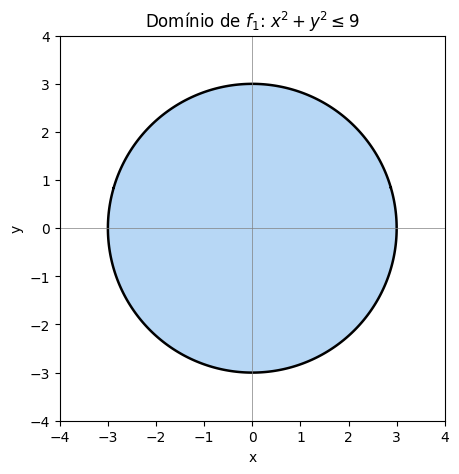

Pontos em que máscara e isfinite discordam: 0 de 641601
(alguns poucos pontos exatamente na fronteira podem divergir por arredondamento)


In [2]:
# 💻 f1: domínio e fronteira
f1 = lambda x, y: np.sqrt(9 - x**2 - y**2)
Z1 = avaliar(f1)

# Condição achada na mão: 9 - x² - y² >= 0
dom1 = 9 - X**2 - Y**2 >= 0

fig, ax = plt.subplots(figsize=(5, 5))
plot_dominio(ax, dom1, fronteira=9 - X**2 - Y**2, incluida=True,
             titulo=r'Domínio de $f_1$: $x^2+y^2 \leq 9$')
plt.show()

conferir_dominio(Z1, dom1)

### $f_2(x,y) = \ln(4 - x^2 - y^2)$

#### Análise na mão ✍️

**Passo 1: o que pode dar errado?**
A função tem um **logaritmo**. O $\ln$ só está definido para números **estritamente positivos**. Por exemplo, $\ln 0$ não existe, porque não há expoente $a$ com $e^a = 0$. Então a parte de dentro do $\ln$ tem que ser **maior que zero**, e não pode ser igual a zero.

**Passo 2: montar a desigualdade e isolar $x^2 + y^2$.**

$$4 - x^2 - y^2 > 0 \iff x^2 + y^2 < 4$$

**Passo 3: identificar a região.** $x^2 + y^2 < 4$ é o **disco aberto de raio 2** centrado na origem.

$$D(f_2) = \lbrace (x,y) \in \mathbb{R}^2 \mid x^2 + y^2 < 4 \rbrace$$

**Passo 4: a fronteira.**

$$x^2 + y^2 = 4 \quad \text{(círculo de raio 2)}$$

**A fronteira está incluída? Não.** Teste o ponto $(2, 0)$:
$f_2(2,0) = \ln(4 - 4 - 0) = \ln 0$, que **não existe**.

> **Regra prática:** desigualdade **estrita** ($<$, $>$) → fronteira **excluída** → desenhada **tracejada**. O domínio é um *disco aberto*.

Compare com $f_1$: lá a raiz aceitava o zero, então a fronteira entrava. Aqui o $\ln$ não aceita o zero, então ela fica de fora.

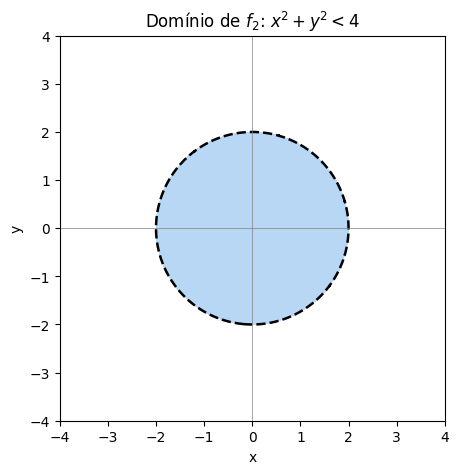

Pontos em que máscara e isfinite discordam: 0 de 641601
(alguns poucos pontos exatamente na fronteira podem divergir por arredondamento)


In [3]:
# 💻 f2: domínio e fronteira
f2 = lambda x, y: np.log(4 - x**2 - y**2)
Z2 = avaliar(f2)

# Condição achada na mão: 4 - x² - y² > 0
dom2 = 4 - X**2 - Y**2 > 0

fig, ax = plt.subplots(figsize=(5, 5))
plot_dominio(ax, dom2, fronteira=4 - X**2 - Y**2, incluida=False,
             titulo=r'Domínio de $f_2$: $x^2+y^2 < 4$')
plt.show()

conferir_dominio(Z2, dom2)

### $f_3(x,y) = \dfrac{1}{x^2 + y^2 - 1}$

#### Análise na mão ✍️

**Passo 1: o que pode dar errado?**
A função é uma **fração**. A única coisa proibida numa fração é **dividir por zero**. Então o denominador tem que ser **diferente de zero**.

**Passo 2: montar a condição e isolar $x^2 + y^2$.**

$$x^2 + y^2 - 1 \neq 0 \iff x^2 + y^2 \neq 1$$

**Passo 3: identificar a região.** $x^2 + y^2 \neq 1$ é o **plano inteiro menos o círculo de raio 1** centrado na origem. O círculo separa o domínio em duas partes: o interior ($x^2 + y^2 < 1$) e o exterior ($x^2 + y^2 > 1$).

$$D(f_3) = \lbrace (x,y) \in \mathbb{R}^2 \mid x^2 + y^2 \neq 1 \rbrace = \mathbb{R}^2 \setminus \lbrace\text{círculo de raio 1}\rbrace$$

**Passo 4: a fronteira.**

$$x^2 + y^2 = 1 \quad \text{(círculo de raio 1)}$$

**A fronteira está incluída? Não.** Teste o ponto $(1, 0)$:
$f_3(1,0) = \dfrac{1}{1 + 0 - 1} = \dfrac{1}{0}$, que **não existe**.

> **Regra prática:** condição com $\neq$ → os pontos da igualdade são **removidos** → fronteira **tracejada**. Aqui a fronteira é justamente o conjunto que foi tirado do plano.

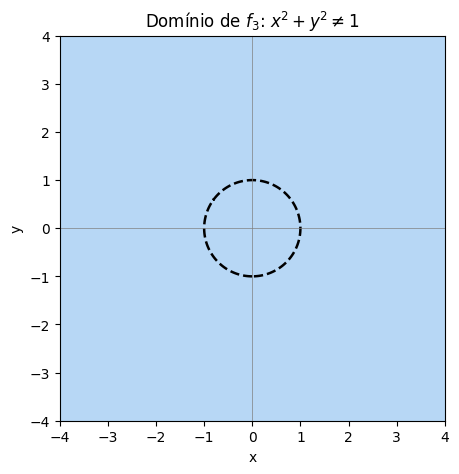

Pontos em que máscara e isfinite discordam: 0 de 641601
(alguns poucos pontos exatamente na fronteira podem divergir por arredondamento)


In [4]:
# 💻 f3: domínio e fronteira
f3 = lambda x, y: 1 / (x**2 + y**2 - 1)
Z3 = avaliar(f3)

# Condição achada na mão: x² + y² - 1 != 0
dom3 = X**2 + Y**2 - 1 != 0

fig, ax = plt.subplots(figsize=(5, 5))
plot_dominio(ax, dom3, fronteira=X**2 + Y**2 - 1, incluida=False,
             titulo=r'Domínio de $f_3$: $x^2+y^2 \neq 1$')
plt.show()

conferir_dominio(Z3, dom3)
# Atenção: o círculo x²+y²=1 é só uma curva; quase nenhum ponto da grade cai
# exatamente nele. Por isso o isfinite "não enxerga" a exclusão: ela é decidida na mão.

---
## Item 2 – Imagem e superfície 3D

> **Enunciado:** Determine a imagem e represente a superfície $z = f(x,y)$ em três dimensões.

**Como este item está organizado**

1. **Configuração do item:** Plotly para gráficos 3D giráveis e funções auxiliares.
2. **Para cada função:**
   - ✍️ **análise na mão:** a imagem, achada a partir do domínio do item 1, e a forma esperada da superfície;
   - 💻 **imagem:** confere os extremos e mostra numericamente os valores que só são *aproximados* (tendendo a $\pm\infty$ ou a 0);
   - 💻 **superfície 3D:** gráfico girável com os pontos e as curvas que definem a imagem marcados.

**Ideia central:** a imagem é o conjunto das **alturas** que a superfície atinge. Nos gráficos 3D, ela é a "projeção" da superfície no eixo $z$.

**Nos gráficos:** arraste para girar, role para dar zoom e passe o mouse para ver $(x, y, z)$. Em $f_2$ e $f_3$ o eixo $z$ é **cortado**, porque a função vai a $\pm\infty$ e não cabe inteira no gráfico.

In [5]:
# 💻 Configuração do item 2: Plotly (3D girável) e funções auxiliares
import plotly.graph_objects as go


def malha_polar(r_min, r_max, n_r=80, n_t=121):
    """Malha em coordenadas polares: x = r·cos(t), y = r·sin(t).
    Como f1, f2 e f3 só dependem de x² + y² = r² (veja a Revisão do item 1),
    essa malha acompanha exatamente as fronteiras circulares: bordas lisas, sem serrilhado."""
    r = np.linspace(r_min, r_max, n_r)
    t = np.linspace(0, 2 * np.pi, n_t)
    R, T = np.meshgrid(r, t)
    return R * np.cos(T), R * np.sin(T)


def superficie(Xs, Ys, Zs, nome):
    return go.Surface(x=Xs, y=Ys, z=Zs, colorscale='Viridis', opacity=0.9, showscale=False, name=nome,
                      hovertemplate='x=%{x:.2f}<br>y=%{y:.2f}<br>z=%{z:.3f}<extra></extra>')


def ponto_3d(x, y, z, nome, cor='red'):
    return go.Scatter3d(x=[x], y=[y], z=[z], mode='markers', marker=dict(size=6, color=cor), name=nome)


def circulo_3d(r, z, nome, tracejado=False, cor='black'):
    t = np.linspace(0, 2 * np.pi, 200)
    return go.Scatter3d(x=r * np.cos(t), y=r * np.sin(t), z=np.full_like(t, z), mode='lines', name=nome,
                        line=dict(color=cor, width=6, dash='dash' if tracejado else 'solid'))


def plano_z(z, nome, lado=3):
    """Plano horizontal translúcido na altura z."""
    v = np.linspace(-lado, lado, 2)
    P, Q = np.meshgrid(v, v)
    return go.Surface(x=P, y=Q, z=np.full_like(P, z), colorscale=[[0, 'gray'], [1, 'gray']],
                      opacity=0.25, showscale=False, name=nome, showlegend=True, hoverinfo='skip')


def mostrar_3d(tracos, titulo, z_range=None, proporcao_real=False):
    """proporcao_real=True mantém a mesma escala nos três eixos (ex.: para a esfera parecer esfera)."""
    cena = dict(xaxis_title='x', yaxis_title='y', zaxis_title='z',
                aspectmode='data' if proporcao_real else 'cube')
    if z_range is not None:
        cena['zaxis'] = dict(range=z_range)
    fig = go.Figure(tracos)
    fig.update_layout(title=titulo, height=620, margin=dict(l=0, r=0, t=50, b=0), scene=cena,
                      legend=dict(x=0, y=0.95, bgcolor='rgba(255,255,255,0.7)'))
    fig.show()


def maximo_na_grade(Z, mascara):
    """Maior valor de Z nos pontos do domínio (grade do item 1) e onde ele ocorre."""
    Zd = np.where(mascara & np.isfinite(Z), Z, np.nan)
    i = np.unravel_index(np.nanargmax(Zd), Z.shape)
    return Zd[i], X[i], Y[i]

### $f_1(x,y) = \sqrt{9 - x^2 - y^2}$

#### Análise na mão ✍️

**Passo 1: substituição.** A função é "raiz de alguma coisa". Chame essa coisa de $u$:

$$u = 9 - (x^2 + y^2) \qquad\Longrightarrow\qquad f_1 = \sqrt{u}$$

**Passo 2: quais valores $u$ assume no domínio?** Do item 1, no domínio vale $0 \le x^2 + y^2 \le 9$.
- Na **origem**, $x^2 + y^2 = 0$ e $u = 9$ (o maior valor de $u$).
- Na **fronteira**, $x^2 + y^2 = 9$ e $u = 0$ (o menor valor de $u$).

A fronteira **pertence** ao domínio, então o valor $u = 0$ é **atingido** de fato. Logo $0 \le u \le 9$.

**Passo 3: aplicar a raiz.** A raiz quadrada é **crescente**: se $u$ aumenta, $\sqrt{u}$ também aumenta. Então ela leva o menor $u$ no menor resultado e o maior $u$ no maior:

$$0 \le u \le 9 \quad\Longrightarrow\quad \sqrt{0} \le \sqrt{u} \le \sqrt{9} \quad\Longrightarrow\quad 0 \le f_1 \le 3$$

**Passo 4: a imagem.**

$$\boxed{\text{Im}(f_1) = [0,\ 3]}$$

Os **dois colchetes são fechados** porque os dois extremos são atingidos:
- o máximo $3$ ocorre na origem: $f_1(0,0) = \sqrt{9} = 3$;
- o mínimo $0$ ocorre em todos os pontos da fronteira, por exemplo $f_1(3,0) = \sqrt{0} = 0$.

**Superfície esperada.** Com $z = \sqrt{9 - x^2 - y^2}$, elevar ao quadrado dá $z^2 = 9 - x^2 - y^2$, ou seja,

$$x^2 + y^2 + z^2 = 9, \quad z \ge 0$$

Essa é a equação da **esfera de raio 3** centrada na origem. A condição $z \ge 0$, que vem da raiz nunca ser negativa, mantém só a **metade de cima**. O gráfico é uma **semiesfera**: topo em $z = 3$ e borda apoiada no plano $z = 0$, exatamente sobre o círculo da fronteira.

In [6]:
# 💻 f1: imagem
print("Valores exatos nos pontos-chave:")
print(f"  f1(0, 0) = {f1(0, 0):.4f}   -> maior valor, atingido na origem")
print(f"  f1(3, 0) = {f1(3, 0):.4f}   -> menor valor, atingido na fronteira (que pertence ao domínio)")

vmax, xM, yM = maximo_na_grade(Z1, dom1)
print(f"\nConferência na grade do item 1: maior valor = {vmax:.4f} em ({xM:.2f}, {yM:.2f})")
print(f"Algum valor da grade fora de [0, 3]? {np.any((Z1[dom1] < 0) | (Z1[dom1] > 3))}")

print("\nConclusão: os dois extremos são ATINGIDOS, então os colchetes são fechados.")
print("Im(f1) = [0, 3]")

Valores exatos nos pontos-chave:
  f1(0, 0) = 3.0000   -> maior valor, atingido na origem
  f1(3, 0) = 0.0000   -> menor valor, atingido na fronteira (que pertence ao domínio)

Conferência na grade do item 1: maior valor = 3.0000 em (0.00, 0.00)
Algum valor da grade fora de [0, 3]? False

Conclusão: os dois extremos são ATINGIDOS, então os colchetes são fechados.
Im(f1) = [0, 3]


In [7]:
# 💻 f1: superfície 3D (arraste para girar)
Xs, Ys = malha_polar(0, 3 - 1e-9)   # o -1e-9 evita a raiz de um "-0.000000000000001" de arredondamento na borda
Zs = f1(Xs, Ys)

mostrar_3d([
    superficie(Xs, Ys, Zs, 'z = f1(x,y)'),
    ponto_3d(0, 0, 3, 'topo (0, 0, 3): máximo, atingido'),
    circulo_3d(3, 0, 'fronteira x²+y²=9, em z = 0: mínimo, atingido'),
], 'f1: semiesfera de raio 3  —  Im(f1) = [0, 3]', proporcao_real=True)

### $f_2(x,y) = \ln(4 - x^2 - y^2)$

#### Análise na mão ✍️

**Passo 1: substituição.**

$$u = 4 - (x^2 + y^2) \qquad\Longrightarrow\qquad f_2 = \ln u$$

**Passo 2: quais valores $u$ assume no domínio?** Do item 1, no domínio vale $0 \le x^2 + y^2 < 4$.
- Na **origem**, $u = 4$ (o maior valor de $u$, atingido).
- Chegando **perto da fronteira**, $x^2 + y^2$ se aproxima de 4 e $u$ se aproxima de 0. Mas a fronteira **não pertence** ao domínio, então $u$ **nunca chega** a 0: fica $0{,}1$, depois $0{,}01$, depois $0{,}001$, e assim por diante.

Logo $0 < u \le 4$, com o lado esquerdo **aberto**.

**Passo 3: aplicar o $\ln$.** O $\ln$ é **crescente**, e quando o argumento se aproxima de 0 pela direita, o $\ln$ vai para $-\infty$:

$$\ln(0{,}1) \approx -2{,}3 \qquad \ln(0{,}001) \approx -6{,}9 \qquad \ln(10^{-9}) \approx -20{,}7 \qquad \dots \qquad \lim_{u \to 0^+} \ln u = -\infty$$

Então:
- o **maior** valor de $f_2$ é $\ln 4 \approx 1{,}386$, atingido na origem;
- **não existe menor** valor: $f_2$ desce sem limite perto da fronteira.

**Passo 4: a imagem.**

$$\boxed{\text{Im}(f_2) = (-\infty,\ \ln 4\,]}$$

- Em $\ln 4$ o colchete é **fechado**, porque esse valor é atingido na origem.
- Do lado esquerdo o intervalo é **ilimitado**. O símbolo $-\infty$ sempre leva parêntese.
- Todo valor menor que $\ln 4$ é atingido: para qualquer altura $c \le \ln 4$, o círculo $x^2 + y^2 = 4 - e^c$ tem altura exatamente $c$.

**Superfície esperada.**
- Um **topo** em $(0,\, 0,\, \ln 4)$.
- Ela **cruza o plano $z = 0$** onde $\ln u = 0$, ou seja, onde $u = 1$: no círculo $x^2 + y^2 = 3$, de raio $\sqrt{3} \approx 1{,}73$. Dentro desse círculo $f_2$ é positiva e fora dele é negativa.
- Perto do círculo de raio 2 ela **despenca** para $-\infty$, como se tivesse uma "parede" invisível no cilindro $x^2 + y^2 = 4$ que nunca é alcançada.

Compare com $f_1$: lá a borda era **atingida**, e a superfície "pousava" no plano. Aqui a borda **não é atingida**, e a superfície "cai para sempre".

In [8]:
# 💻 f2: imagem
print("Valor exato no ponto-chave:")
print(f"  f2(0, 0) = {f2(0, 0):.4f} = ln 4   -> maior valor, atingido na origem")

vmax, xM, yM = maximo_na_grade(Z2, dom2)
print(f"\nConferência na grade do item 1: maior valor = {vmax:.4f} em ({xM:.2f}, {yM:.2f})")

print("\nAproximando da fronteira (r = distância até a origem, r -> 2), f2 diminui sem limite:")
for r in [1.9, 1.99, 1.999, 1.9999, 1.99999]:
    print(f"  r = {r:<8}  u = 4 - r² = {4 - r**2:.6f}   f2 = ln(u) = {np.log(4 - r**2):9.4f}")
print("  ... e a fronteira r = 2 não pertence ao domínio, então nunca há um 'último' valor.")

print("\nConclusão: o máximo ln 4 é atingido (colchete fechado); não existe mínimo (f2 -> -∞).")
print(f"Im(f2) = (-∞, ln 4]  ≈ (-∞, {np.log(4):.4f}]")

Valor exato no ponto-chave:
  f2(0, 0) = 1.3863 = ln 4   -> maior valor, atingido na origem

Conferência na grade do item 1: maior valor = 1.3863 em (0.00, 0.00)

Aproximando da fronteira (r = distância até a origem, r -> 2), f2 diminui sem limite:
  r = 1.9       u = 4 - r² = 0.390000   f2 = ln(u) =   -0.9416
  r = 1.99      u = 4 - r² = 0.039900   f2 = ln(u) =   -3.2214
  r = 1.999     u = 4 - r² = 0.003999   f2 = ln(u) =   -5.5217
  r = 1.9999    u = 4 - r² = 0.000400   f2 = ln(u) =   -7.8241
  r = 1.99999   u = 4 - r² = 0.000040   f2 = ln(u) =  -10.1266
  ... e a fronteira r = 2 não pertence ao domínio, então nunca há um 'último' valor.

Conclusão: o máximo ln 4 é atingido (colchete fechado); não existe mínimo (f2 -> -∞).
Im(f2) = (-∞, ln 4]  ≈ (-∞, 1.3863]


In [9]:
# 💻 f2: superfície 3D (arraste para girar)
z_corte = -5                                   # a superfície vai a -∞: mostramos só até z = -5
r_corte = np.sqrt(4 - np.exp(z_corte))         # raio onde f2 = -5  (de ln(4 - r²) = -5)
Xs, Ys = malha_polar(0, r_corte)
Zs = f2(Xs, Ys)

mostrar_3d([
    superficie(Xs, Ys, Zs, 'z = f2(x,y)'),
    ponto_3d(0, 0, np.log(4), 'topo (0, 0, ln 4): máximo, atingido'),
    circulo_3d(np.sqrt(3), 0, 'cruza z = 0 em x²+y²=3', cor='white'),
    circulo_3d(2, z_corte, 'fronteira x²+y²=4 (excluída): f2 -> -∞', tracejado=True),
], f'f2: topo em ln 4, despenca para -∞ na borda (eixo z cortado em {z_corte})  —  Im(f2) = (-∞, ln 4]',
   z_range=[z_corte - 0.2, 2])

### $f_3(x,y) = \dfrac{1}{x^2 + y^2 - 1}$

#### Análise na mão ✍️

**Passo 1: substituição.**

$$u = x^2 + y^2 - 1 \qquad\Longrightarrow\qquad f_3 = \frac{1}{u}$$

**Passo 2: quais valores $u$ assume no domínio?** Como $x^2 + y^2 \ge 0$, sempre vale $u \ge -1$. Do item 1, $u \ne 0$. O sinal de $u$ **muda** ao atravessar o círculo, e $\frac{1}{u}$ se comporta de forma bem diferente para $u$ negativo e para $u$ positivo. Por isso a análise é feita **separadamente nas duas partes do domínio** que apareceram no item 1:

| Parte do domínio | Valores de $x^2 + y^2$ | Valores de $u$ |
|:---:|:---:|:---:|
| interior | $0 \le x^2 + y^2 < 1$ | $-1 \le u < 0$ |
| exterior | $x^2 + y^2 > 1$ | $u > 0$ (sem limite superior) |

**Passo 3: aplicar $\frac{1}{u}$ em cada parte.**

*Interior* ($-1 \le u < 0$):
- na **origem**, $u = -1$ e $f_3 = \frac{1}{-1} = -1$;
- perto do círculo, $u \to 0^-$ (negativo e cada vez menor em módulo), e $\frac{1}{u} \to -\infty$. Por exemplo, $\frac{1}{-0{,}01} = -100$.

Os valores vão de $-1$ (na origem) até $-\infty$. Então **$-1$ é o MAIOR valor** dessa parte: a superfície tem um "topo" em $z = -1$ e desce a partir dele.

$$\text{interior: } (-\infty,\ -1\,]$$

*Exterior* ($u > 0$):
- perto do círculo, $u \to 0^+$ e $\frac{1}{u} \to +\infty$;
- longe da origem, $u \to +\infty$ e $\frac{1}{u} \to 0^+$, mas **nunca chega a 0** (uma fração com numerador 1 nunca é zero).

$$\text{exterior: } (0,\ +\infty)$$

**Passo 4: a imagem.** É a união das duas partes:

$$\boxed{\text{Im}(f_3) = (-\infty,\ -1\,] \ \cup\ (0,\ +\infty)}$$

- Em $-1$ o colchete é **fechado**: o valor é atingido na origem.
- Em $0$ o parêntese é **aberto**: o valor é só aproximado, nunca atingido.
- **Buraco** $(-1,\, 0\,]$: nenhuma altura entre $-1$ (exclusive) e $0$ (inclusive) aparece. O zero não aparece porque $\frac{1}{u} \ne 0$. Valores em $(-1, 0)$ exigiriam $u < -1$, o que é impossível.

**Superfície esperada.** São duas partes separadas pelo círculo unitário, onde a função "explode":
- **Dentro:** uma "cúpula invertida" **abaixo** do plano $z = 0$. O topo fica em $(0,\, 0,\, -1)$ e a superfície despenca para $-\infty$ ao se aproximar do círculo.
- **Fora:** uma superfície **acima** do plano $z = 0$. Ela sobe para $+\infty$ junto ao círculo e desce suavemente, aproximando-se do plano $z = 0$ sem tocá-lo à medida que se afasta da origem.
- **Entre os planos $z = -1$ e $z = 0$ não há nenhum ponto da superfície**: é o buraco da imagem visto no gráfico.

In [10]:
# 💻 f3: imagem
print("Valor exato no ponto-chave:")
print(f"  f3(0, 0) = {f3(0, 0):.4f}   -> maior valor da parte de DENTRO, atingido na origem")

print("\nDentro, aproximando do círculo (r -> 1⁻): f3 -> -∞")
for r in [0.9, 0.99, 0.999, 0.9999]:
    print(f"  r = {r:<7}  f3 = {1 / (r**2 - 1):14.2f}")

print("\nFora, aproximando do círculo (r -> 1⁺): f3 -> +∞")
for r in [1.1, 1.01, 1.001, 1.0001]:
    print(f"  r = {r:<7}  f3 = {1 / (r**2 - 1):14.2f}")

print("\nFora, afastando da origem (r -> ∞): f3 -> 0⁺, mas nunca chega a 0")
for r in [10, 100, 1000, 10000]:
    print(f"  r = {r:<7}  f3 = {1 / (r**2 - 1):.10f}")

no_buraco = np.sum((Z3 > -1) & (Z3 <= 0))
print(f"\nPontos da grade do item 1 com f3 no 'buraco' (-1, 0]: {no_buraco}")

print("\nConclusão: dentro, Im = (-∞, -1] (máximo -1 na origem); fora, Im = (0, +∞).")
print("Im(f3) = (-∞, -1] ∪ (0, +∞)   — nenhum valor em (-1, 0] é atingido.")

Valor exato no ponto-chave:
  f3(0, 0) = -1.0000   -> maior valor da parte de DENTRO, atingido na origem

Dentro, aproximando do círculo (r -> 1⁻): f3 -> -∞
  r = 0.9      f3 =          -5.26
  r = 0.99     f3 =         -50.25
  r = 0.999    f3 =        -500.25
  r = 0.9999   f3 =       -5000.25

Fora, aproximando do círculo (r -> 1⁺): f3 -> +∞
  r = 1.1      f3 =           4.76
  r = 1.01     f3 =          49.75
  r = 1.001    f3 =         499.75
  r = 1.0001   f3 =        4999.75

Fora, afastando da origem (r -> ∞): f3 -> 0⁺, mas nunca chega a 0
  r = 10       f3 = 0.0101010101
  r = 100      f3 = 0.0001000100
  r = 1000     f3 = 0.0000010000
  r = 10000    f3 = 0.0000000100

Pontos da grade do item 1 com f3 no 'buraco' (-1, 0]: 0

Conclusão: dentro, Im = (-∞, -1] (máximo -1 na origem); fora, Im = (0, +∞).
Im(f3) = (-∞, -1] ∪ (0, +∞)   — nenhum valor em (-1, 0] é atingido.


In [11]:
# 💻 f3: superfície 3D (arraste para girar)
z_corte = 6                                    # f3 vai a ±∞ junto ao círculo: mostramos só |z| <= 6
r_dentro = np.sqrt(1 - 1 / z_corte)            # raio onde f3 = -6 (parte de dentro)
r_fora = np.sqrt(1 + 1 / z_corte)              # raio onde f3 = +6 (parte de fora)

Xd, Yd = malha_polar(0, r_dentro)              # interior: x² + y² < 1
Xf, Yf = malha_polar(r_fora, 3)                # exterior: x² + y² > 1

mostrar_3d([
    superficie(Xd, Yd, f3(Xd, Yd), 'dentro: z = f3 < 0'),
    superficie(Xf, Yf, f3(Xf, Yf), 'fora: z = f3 > 0'),
    ponto_3d(0, 0, -1, 'topo da parte de dentro (0, 0, -1)'),
    circulo_3d(1, 0, 'círculo x²+y²=1 (excluído): f3 -> ±∞', tracejado=True),
    plano_z(-1, 'plano z = -1'),
    plano_z(0, 'plano z = 0  (entre os dois planos: nenhum ponto)'),
], f'f3: duas partes separadas pelo círculo unitário (eixo z cortado em ±{z_corte})  —  Im(f3) = (-∞, -1] ∪ (0, +∞)',
   z_range=[-z_corte - 0.2, z_corte + 0.2])

---
## Itens 3 e 5 – Curvas de nível e valores de $c$ sem curva

> **Item 3:** Desenhe curvas de nível $f(x,y) = c$, com um controle interativo para variar $c$.
>
> **Item 5:** Explique por que certos valores de $c$ não produzem curvas de nível e relacione isso à imagem da função.

**Por que juntos?** O item 3 desenha a curva para cada $c$. O item 5 explica o que acontece quando o mesmo controle chega num $c$ que **não** produz curva. É o mesmo slider e a mesma conta: ao isolar $x^2 + y^2$ na equação $f(x,y) = c$, aparece tanto o raio da curva (item 3) quanto a condição para ela existir (item 5).

**O que é uma curva de nível.** É o conjunto dos pontos do domínio onde a função tem altura $c$:

$$\lbrace (x,y) \in D \mid f(x,y) = c \rbrace$$

Geometricamente, é o corte da superfície $z = f(x,y)$ pelo plano horizontal $z = c$, visto de cima. É como as linhas de um mapa topográfico, que ligam pontos de mesma altitude.

**A resposta geral do item 5.** Pela definição de imagem:

$$\text{existe curva de nível } c \iff \text{existe } (x,y) \in D \text{ com } f(x,y) = c \iff c \in \text{Im}(f)$$

Ou seja, **um valor $c$ produz curva se e somente se ele está na imagem**. Geometricamente, o plano $z = c$ só corta a superfície se a superfície atinge a altura $c$. Para cada função, abaixo, essa conclusão é confirmada pela própria conta da curva de nível, que dá exatamente a imagem achada no item 2.

**Como este item está organizado**

1. **Configuração:** funções auxiliares do slider.
2. **Para cada função:**
   - ✍️ **análise na mão:** a equação da curva e o raio $r(c)$ (item 3), e quais $c$ não dão curva e por quê (item 5);
   - 💻 **slider interativo**, com duas vistas:
     - à esquerda, a superfície cortada pelo plano $z = c$;
     - à direita, a curva no plano xy, com a mensagem explicando o resultado para aquele $c$;
   - 💻 **tabela** com o resultado para alguns valores de $c$.

**No gráfico da direita:**
- **azul:** curva achada **numericamente**, procurando na grade os pontos com $f = c$, sem usar nenhuma fórmula;
- **vermelho pontilhado:** círculo da fórmula $r(c)$ achada **na mão**. Se coincidir com o azul, a fórmula está certa;
- **cinza:** fronteira do domínio, cheia se incluída e tracejada se excluída.

In [12]:
# 💻 Configuração dos itens 3 e 5: slider de curvas de nível
from plotly.subplots import make_subplots


def curva_numerica(Z, c, passo=3):
    """Acha NUMERICAMENTE os pontos da grade do item 1 onde Z = c (sem usar a fórmula r(c)).
    Devolve listas xs, ys; None separa pedaços diferentes da curva."""
    Zc = np.where(np.isfinite(Z), Z, np.nan)
    if not (np.nanmin(Zc) <= c <= np.nanmax(Zc)):
        return [], []                      # nenhum ponto tem altura c
    fig_tmp, ax_tmp = plt.subplots()
    segmentos = ax_tmp.contour(X, Y, Zc, levels=[c]).allsegs[0]
    plt.close(fig_tmp)
    xs, ys = [], []
    for seg in segmentos:
        seg = np.vstack([seg[::passo], seg[-1:]])
        xs += list(seg[:, 0]) + [None]
        ys += list(seg[:, 1]) + [None]
    return xs, ys


def circulo_xy(r, n=200):
    t = np.linspace(0, 2 * np.pi, n)
    return r * np.cos(t), r * np.sin(t)


def slider_curvas(titulo, Z, valores_c, analisar, superficies, fronteira, z_range, lim_xy, c_inicial):
    """Monta a figura interativa: superfície + plano z = c (esquerda) e curva de nível (direita).
    analisar(c) -> (tem_curva, raio_ou_None, mensagem) é a análise feita na mão."""
    fig = make_subplots(rows=1, cols=2, specs=[[{'type': 'scene'}, {'type': 'xy'}]],
                        column_widths=[0.55, 0.45], horizontal_spacing=0.06,
                        subplot_titles=('Superfície cortada pelo plano z = c', 'Curva de nível no plano xy'))

    # --- traços fixos (aparecem para todo c)
    for s in superficies:
        fig.add_trace(s, row=1, col=1)
    r_f, incluida = fronteira
    fx, fy = circulo_xy(r_f)
    fig.add_trace(go.Scatter(x=fx, y=fy, mode='lines', name='fronteira do domínio',
                             line=dict(color='gray', width=2, dash='solid' if incluida else 'dash')), row=1, col=2)
    n_fixos = len(fig.data)

    # --- 4 traços para cada c (só os do c escolhido ficam visíveis)
    mensagens = []
    for c in valores_c:
        tem, r, msg = analisar(c)
        mensagens.append(msg)
        if tem and r == 0:                 # curva degenerada: um ponto só (a origem)
            xs, ys, modo = [0], [0], 'markers'
        else:
            xs, ys = curva_numerica(Z, c)
            modo = 'lines'
        zs = [None if v is None else c for v in xs]
        rx, ry = circulo_xy(r) if (tem and r > 0) else ([], [])

        plano = plano_z(c, f'plano z = {c:.3g}', lado=lim_xy)
        plano.update(visible=False, showlegend=False)
        fig.add_trace(plano, row=1, col=1)
        fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode=modo, visible=False, showlegend=False,
                                   line=dict(color='blue', width=7), marker=dict(size=6, color='blue')), row=1, col=1)
        fig.add_trace(go.Scatter(x=xs, y=ys, mode=modo, visible=False, name='curva numérica (f = c na grade)',
                                 line=dict(color='blue', width=3), marker=dict(size=9, color='blue')), row=1, col=2)
        fig.add_trace(go.Scatter(x=rx, y=ry, mode='lines', visible=False, name='fórmula r(c) da análise na mão',
                                 line=dict(color='red', width=2, dash='dot')), row=1, col=2)

    # --- passos do slider
    passos = []
    for i, (c, msg) in enumerate(zip(valores_c, mensagens)):
        vis = [True] * n_fixos + [False] * (len(fig.data) - n_fixos)
        for j in range(4):
            vis[n_fixos + 4 * i + j] = True
        passos.append(dict(method='update', label=f'{c:.3g}',
                           args=[{'visible': vis}, {'title.text': f'{titulo}<br><sub>{msg}</sub>'}]))

    i0 = int(np.argmin(np.abs(np.array(valores_c) - c_inicial)))
    for tr, v in zip(fig.data, passos[i0]['args'][0]['visible']):
        tr.visible = v

    fig.update_layout(
        title=dict(text=f'{titulo}<br><sub>{mensagens[i0]}</sub>', x=0.01),
        height=650, margin=dict(l=10, r=10, t=110, b=10),
        sliders=[dict(active=i0, steps=passos, currentvalue=dict(prefix='c = '), pad=dict(t=30))],
        scene=dict(xaxis_title='x', yaxis_title='y', zaxis_title='z', aspectmode='cube',
                   zaxis=dict(range=z_range)),
        legend=dict(x=0.56, y=-0.02, orientation='h'),
    )
    fig.update_xaxes(range=[-lim_xy, lim_xy], title='x', row=1, col=2)
    fig.update_yaxes(range=[-lim_xy, lim_xy], title='y', scaleanchor='x', scaleratio=1, row=1, col=2)
    fig.show()


def tabela_c(valores, analisar):
    """Imprime o resultado da análise para alguns valores de c."""
    for c in valores:
        tem, r, msg = analisar(c)
        print(('  ✅ ' if tem else '  ❌ ') + msg)

### $f_1(x,y) = \sqrt{9 - x^2 - y^2}$

#### Análise na mão ✍️

##### Item 3: equação das curvas de nível

**Passo 1: igualar a $c$.**

$$\sqrt{9 - x^2 - y^2} = c$$

**Passo 2: isolar $x^2 + y^2$.** O lado esquerdo é uma raiz, então **nunca é negativo**. Por isso a igualdade só é possível se $c \ge 0$, e só nesse caso podemos elevar os dois lados ao quadrado:

$$9 - x^2 - y^2 = c^2 \quad\Longrightarrow\quad x^2 + y^2 = 9 - c^2$$

**Passo 3: identificar a curva.** É um círculo centrado na origem (veja a Revisão do item 1) com raio

$$r(c) = \sqrt{9 - c^2}$$

**Passo 4: como as curvas mudam com $c$.**

| $c$ | $r(c) = \sqrt{9 - c^2}$ | O que é |
|:---:|:---:|:---|
| 0 | 3 | a própria fronteira do domínio (a borda da semiesfera) |
| 1 | ≈ 2,83 | |
| 2 | ≈ 2,24 | |
| 2,5 | ≈ 1,66 | |
| 3 | 0 | só a origem (o topo) |

- Quanto **maior** o $c$, **menor** o círculo, porque se sobe em direção ao topo da semiesfera.
- De $c = 0$ para $c = 1$ o raio quase não muda (de 3 para 2,83), mas de $c = 2$ para $c = 3$ ele cai de 2,24 para 0. Círculos **juntos** significam que a altura muda rápido num espaço pequeno: a superfície é **íngreme perto da borda** e **plana perto do topo**, como uma semiesfera.

##### Item 5: valores de $c$ sem curva

A curva existe quando as duas condições dos passos 2 e 3 valem ao mesmo tempo:
- $c \ge 0$ (passo 2: a raiz nunca é negativa);
- $r(c)^2 = 9 - c^2 \ge 0$ (passo 3: um círculo não tem raio ao quadrado negativo), ou seja, $c \le 3$.

$$\text{existe curva} \iff 0 \le c \le 3$$

**Para $c < 0$:** $f_1$ é uma raiz e nunca vale um número negativo. Geometricamente, o plano $z = c$ passa **abaixo** da semiesfera.

> ⚠️ **Armadilha:** quem eleva ao quadrado sem verificar o sinal de $c$ chega, para $c = -2$, em $x^2 + y^2 = 5$, que parece um círculo válido! Mas ao testar um ponto dele, como $(\sqrt{5}, 0)$, obtém-se $f_1 = \sqrt{9 - 5} = 2 \ne -2$. Elevar ao quadrado **cria soluções falsas**, e por isso a condição $c \ge 0$ do passo 2 é essencial.

**Para $c > 3$:** seria preciso $x^2 + y^2 = 9 - c^2 < 0$, o que é impossível. Geometricamente, o plano $z = c$ passa **acima** do topo da semiesfera, cuja altura máxima é 3.

**Relação com a imagem:** os $c$ que produzem curva formam $[0,\ 3]$, que é exatamente $\text{Im}(f_1)$, achada no item 2.

In [13]:
# 💻 f1: análise de cada c (a mesma da célula ✍️, traduzida para código)
def analisar_f1(c):
    if c < 0:
        return False, None, f"c = {c:g}: sem curva. f1 é uma raiz, nunca é negativa (o plano passa abaixo da semiesfera)."
    if c > 3:
        return False, None, f"c = {c:g}: sem curva. A maior altura de f1 é 3, na origem (o plano passa acima do topo)."
    r = np.sqrt(9 - c**2)
    if r == 0:
        return True, 0.0, "c = 3: a curva se reduz a um ponto, a origem (o topo da semiesfera)."
    extra = " (é a própria fronteira do domínio)" if c == 0 else ""
    return True, r, f"c = {c:g}: círculo x² + y² = {9 - c**2:g}, raio ≈ {r:.3f}{extra}."


tabela_c([-1, 0, 1, 2, 2.9, 3, 3.5], analisar_f1)

  ❌ c = -1: sem curva. f1 é uma raiz, nunca é negativa (o plano passa abaixo da semiesfera).
  ✅ c = 0: círculo x² + y² = 9, raio ≈ 3.000 (é a própria fronteira do domínio).
  ✅ c = 1: círculo x² + y² = 8, raio ≈ 2.828.
  ✅ c = 2: círculo x² + y² = 5, raio ≈ 2.236.
  ✅ c = 2.9: círculo x² + y² = 0.59, raio ≈ 0.768.
  ✅ c = 3: a curva se reduz a um ponto, a origem (o topo da semiesfera).
  ❌ c = 3.5: sem curva. A maior altura de f1 é 3, na origem (o plano passa acima do topo).


In [14]:
# 💻 f1: slider de curvas de nível (mova o slider abaixo do gráfico; a superfície pode ser girada)
# Em c = 0 a curva azul aparece só em pedaços: ela fica exatamente na borda do domínio, onde a grade
# mal tem pontos com f1 = 0. O círculo vermelho (fórmula) mostra a curva completa: a própria fronteira.
Xs, Ys = malha_polar(0, 3 - 1e-9)
slider_curvas(
    titulo='f1(x,y) = √(9 − x² − y²)',
    Z=Z1,
    valores_c=list(np.round(np.arange(-1, 4.001, 0.25), 2)),   # inclui valores fora de Im(f1) = [0, 3]
    analisar=analisar_f1,
    superficies=[superficie(Xs, Ys, f1(Xs, Ys), 'z = f1(x,y)')],
    fronteira=(3, True),
    z_range=[-1.2, 4.2],
    lim_xy=3.5,
    c_inicial=2,
)

### $f_2(x,y) = \ln(4 - x^2 - y^2)$

#### Análise na mão ✍️

##### Item 3: equação das curvas de nível

**Passo 1: igualar a $c$.**

$$\ln(4 - x^2 - y^2) = c$$

**Passo 2: isolar $x^2 + y^2$.** Para desfazer o $\ln$, aplique a exponencial dos dois lados, usando $e^{\ln a} = a$:

$$4 - x^2 - y^2 = e^c \quad\Longrightarrow\quad x^2 + y^2 = 4 - e^c$$

Ao contrário de $f_1$, aqui não há nenhuma restrição escondida neste passo: a exponencial está definida para qualquer $c$.

**Passo 3: identificar a curva.** Círculo centrado na origem com raio

$$r(c) = \sqrt{4 - e^c}$$

**Passo 4: como as curvas mudam com $c$.**

| $c$ | $e^c$ | $r(c) = \sqrt{4 - e^c}$ | O que é |
|:---:|:---:|:---:|:---|
| −3 | ≈ 0,050 | ≈ 1,99 | |
| −1 | ≈ 0,368 | ≈ 1,91 | |
| 0 | 1 | ≈ 1,73 | onde a superfície cruza o plano $z = 0$ (item 2) |
| 1 | ≈ 2,718 | ≈ 1,13 | |
| $\ln 4 \approx 1{,}386$ | 4 | 0 | só a origem (o topo) |

- Quanto **maior** o $c$, **menor** o círculo, como em $f_1$.
- Quando $c \to -\infty$, $e^c \to 0$ e $r(c) \to 2$: os círculos se **acumulam** perto da fronteira, **sem nunca chegar** nela. É a superfície despencando para $-\infty$ junto à borda (item 2).

##### Item 5: valores de $c$ sem curva

A curva existe quando $r(c)^2 = 4 - e^c \ge 0$:

$$e^c \le 4 \iff c \le \ln 4$$

**Para $c > \ln 4$:** seria preciso $x^2 + y^2 = 4 - e^c < 0$, o que é impossível. Geometricamente, o plano $z = c$ passa **acima** do topo, cuja altura máxima é $\ln 4$.

**Não há limite inferior:** como $e^c > 0$ para **qualquer** $c$, o raio $r(c) = \sqrt{4 - e^c}$ existe e é menor que 2 para todo $c \le \ln 4$, mesmo para $c = -100$. Qualquer valor negativo, por menor que seja, tem curva.

**Relação com a imagem:** os $c$ que produzem curva formam $(-\infty,\ \ln 4\,]$, que é exatamente $\text{Im}(f_2)$, achada no item 2.

In [15]:
# 💻 f2: análise de cada c
LN4 = np.log(4)

def analisar_f2(c):
    if c > LN4 + 1e-12:
        return False, None, f"c = {c:g}: sem curva. c > ln 4 ≈ 1.386, a maior altura de f2 (o plano passa acima do topo)."
    r2 = 4 - np.exp(c)
    if r2 < 1e-12:
        return True, 0.0, "c = ln 4 ≈ 1.386: a curva se reduz a um ponto, a origem (o topo)."
    return True, np.sqrt(r2), f"c = {c:.3g}: círculo x² + y² = 4 − e^c ≈ {r2:.3f}, raio ≈ {np.sqrt(r2):.6g} (sempre < 2: nunca toca a fronteira)."


tabela_c([-10, -3, 0, 1, LN4, 1.5, 3], analisar_f2)

  ✅ c = -10: círculo x² + y² = 4 − e^c ≈ 4.000, raio ≈ 1.99999 (sempre < 2: nunca toca a fronteira).
  ✅ c = -3: círculo x² + y² = 4 − e^c ≈ 3.950, raio ≈ 1.98751 (sempre < 2: nunca toca a fronteira).
  ✅ c = 0: círculo x² + y² = 4 − e^c ≈ 3.000, raio ≈ 1.73205 (sempre < 2: nunca toca a fronteira).
  ✅ c = 1: círculo x² + y² = 4 − e^c ≈ 1.282, raio ≈ 1.13213 (sempre < 2: nunca toca a fronteira).
  ✅ c = ln 4 ≈ 1.386: a curva se reduz a um ponto, a origem (o topo).
  ❌ c = 1.5: sem curva. c > ln 4 ≈ 1.386, a maior altura de f2 (o plano passa acima do topo).
  ❌ c = 3: sem curva. c > ln 4 ≈ 1.386, a maior altura de f2 (o plano passa acima do topo).


In [16]:
# 💻 f2: slider de curvas de nível
z_corte = -5
Xs, Ys = malha_polar(0, np.sqrt(4 - np.exp(z_corte)))
valores = sorted(set(np.round(np.arange(-4, 2.501, 0.25), 2)) | {LN4})   # inclui ln 4 e valores acima dele
slider_curvas(
    titulo='f2(x,y) = ln(4 − x² − y²)',
    Z=Z2,
    valores_c=valores,
    analisar=analisar_f2,
    superficies=[superficie(Xs, Ys, f2(Xs, Ys), 'z = f2(x,y)')],
    fronteira=(2, False),
    z_range=[z_corte - 0.2, 2.7],
    lim_xy=2.5,
    c_inicial=0,
)

### $f_3(x,y) = \dfrac{1}{x^2 + y^2 - 1}$

#### Análise na mão ✍️

##### Item 3: equação das curvas de nível

**Passo 1: igualar a $c$.**

$$\frac{1}{x^2 + y^2 - 1} = c$$

**Passo 2: isolar $x^2 + y^2$.** Para inverter a fração é preciso $c \ne 0$. Se $c = 0$ não há solução, porque uma fração com numerador 1 nunca vale zero. Para $c \ne 0$:

$$x^2 + y^2 - 1 = \frac{1}{c} \quad\Longrightarrow\quad x^2 + y^2 = 1 + \frac{1}{c}$$

**Passo 3: identificar a curva.** Círculo centrado na origem com raio

$$r(c) = \sqrt{1 + \frac{1}{c}}$$

**Passo 4: como as curvas mudam com $c$.**

| $c$ | $1 + 1/c$ | $r(c)$ | Onde fica |
|:---:|:---:|:---:|:---|
| −4 | 0,75 | ≈ 0,87 | dentro do círculo unitário |
| −2 | 0,5 | ≈ 0,71 | dentro |
| −1 | 0 | 0 | só a origem (o topo da parte de dentro) |
| 0,5 | 3 | ≈ 1,73 | fora |
| 1 | 2 | ≈ 1,41 | fora |
| 4 | 1,25 | ≈ 1,12 | fora |

- **$c > 0$:** $r > 1$, as curvas ficam **fora** do círculo unitário. Quando $c \to 0^+$, o raio cresce sem limite: alturas positivas pequenas ficam longe da origem.
- **$c \le -1$:** $r < 1$, as curvas ficam **dentro**.
- **Quando $|c| \to \infty$:** $r(c) \to 1$, e as curvas se **acumulam em volta do círculo excluído**, por dentro e por fora. É onde a função explode para $\pm\infty$.

##### Item 5: valores de $c$ sem curva

A curva existe quando $c \ne 0$ (passo 2) e $r(c)^2 = 1 + \frac{1}{c} \ge 0$ (passo 3). Separando pelo sinal de $c$:

- **$c > 0$:** $\frac{1}{c} > 0$, então $1 + \frac{1}{c} > 1 > 0$. ✅ Sempre tem curva.
- **$c < 0$:** é preciso $\frac{1}{c} \ge -1$. Multiplicando os dois lados por $c$, que é **negativo**, a desigualdade **inverte**: $1 \le -c$, ou seja, $c \le -1$.
- **$c = 0$:** ❌ sem curva (passo 2).

$$\text{existe curva} \iff c \le -1 \ \text{ ou } \ c > 0$$

**Para $-1 < c \le 0$ não há curva.** Esse é o buraco da imagem visto no item 2:
- dentro do círculo unitário, $f_3 \le -1$, porque a superfície nunca sobe acima de $-1$;
- fora do círculo, $f_3 > 0$, porque a superfície nunca desce até 0.

Geometricamente, o plano $z = c$ com $-1 < c \le 0$ passa **pelo vão entre as duas partes** da superfície, sem tocar nenhuma delas. No slider isso aparece claramente.

**Relação com a imagem:** os $c$ que produzem curva formam $(-\infty,\ -1\,] \cup (0,\ +\infty)$, que é exatamente $\text{Im}(f_3)$, achada no item 2.

In [17]:
# 💻 f3: análise de cada c
def analisar_f3(c):
    if c == 0:
        return False, None, "c = 0: sem curva. Uma fração com numerador 1 nunca vale 0 (fora do círculo, f3 só se aproxima de 0)."
    if -1 < c < 0:
        return False, None, (f"c = {c:g}: sem curva. Exigiria x² + y² = 1 + 1/c = {1 + 1/c:.3g} < 0. "
                             "Dentro f3 ≤ −1 e fora f3 > 0: o plano passa no vão entre as duas partes.")
    r2 = 1 + 1 / c
    if abs(r2) < 1e-12:
        return True, 0.0, "c = -1: a curva se reduz a um ponto, a origem (o topo da parte de dentro)."
    lado = "fora" if c > 0 else "dentro"
    return True, np.sqrt(r2), f"c = {c:g}: círculo x² + y² = 1 + 1/c = {r2:.3g}, raio ≈ {np.sqrt(r2):.3f} ({lado} do círculo unitário)."


tabela_c([-4, -1, -0.5, 0, 0.5, 1, 4], analisar_f3)

  ✅ c = -4: círculo x² + y² = 1 + 1/c = 0.75, raio ≈ 0.866 (dentro do círculo unitário).
  ✅ c = -1: a curva se reduz a um ponto, a origem (o topo da parte de dentro).
  ❌ c = -0.5: sem curva. Exigiria x² + y² = 1 + 1/c = -1 < 0. Dentro f3 ≤ −1 e fora f3 > 0: o plano passa no vão entre as duas partes.
  ❌ c = 0: sem curva. Uma fração com numerador 1 nunca vale 0 (fora do círculo, f3 só se aproxima de 0).
  ✅ c = 0.5: círculo x² + y² = 1 + 1/c = 3, raio ≈ 1.732 (fora do círculo unitário).
  ✅ c = 1: círculo x² + y² = 1 + 1/c = 2, raio ≈ 1.414 (fora do círculo unitário).
  ✅ c = 4: círculo x² + y² = 1 + 1/c = 1.25, raio ≈ 1.118 (fora do círculo unitário).


In [18]:
# 💻 f3: slider de curvas de nível
z_corte = 6
Xd, Yd = malha_polar(0, np.sqrt(1 - 1 / z_corte))
Xf, Yf = malha_polar(np.sqrt(1 + 1 / z_corte), 3)

# Junto ao círculo unitário f3 salta de -∞ para +∞. Entre dois pontos vizinhos da grade, um de cada lado,
# o contour "acharia" uma falsa travessia de qualquer nível c. Por isso a faixa |x² + y² − 1| < 0.05,
# onde |f3| > 20 (fora do intervalo de c do slider), é ignorada na busca numérica.
Z3_curvas = np.where(np.abs(X**2 + Y**2 - 1) < 0.05, np.nan, Z3)

slider_curvas(
    titulo='f3(x,y) = 1/(x² + y² − 1)',
    Z=Z3_curvas,
    valores_c=list(np.round(np.arange(-4, 4.001, 0.25), 2)),   # inclui o "buraco" (-1, 0]
    analisar=analisar_f3,
    superficies=[superficie(Xd, Yd, f3(Xd, Yd), 'dentro'), superficie(Xf, Yf, f3(Xf, Yf), 'fora')],
    fronteira=(1, False),
    z_range=[-z_corte - 0.2, z_corte + 0.2],
    lim_xy=3,
    c_inicial=1,
)

---
## Item 4 – Verificar se um ponto $(a, b)$ pertence ao domínio

> **Enunciado:** Permita ao usuário escolher um ponto $(a,b)$ e explique se ele pertence ao domínio e, caso contrário, qual condição matemática falhou.

**Como este item está organizado**

1. ✍️ **Análise na mão:** como testar um ponto e exemplos resolvidos, incluindo pontos na fronteira.
2. 💻 **Por que cálculo exato:** um exemplo em que a conta com decimais do computador dá a resposta **errada**.
3. 💻 **Configuração:** leitura exata dos números (SymPy) e as funções de verificação.
4. 💻 **Verificador interativo:** o usuário digita $a$ e $b$, e o programa testa as três funções, explica cada resultado e marca o ponto nos gráficos do item 1.

#### Análise na mão ✍️

**Ideia.** Um ponto $(a, b)$ pertence ao domínio **se e somente se** satisfaz a condição de existência encontrada no item 1. Basta substituir $x = a$ e $y = b$ e verificar. Se a condição falhar, ela própria diz **o motivo**.

| Função | Condição de existência | Se falhar, o motivo é |
|:---:|:---:|:---|
| $f_1 = \sqrt{9 - x^2 - y^2}$ | $9 - a^2 - b^2 \ge 0$ | raiz quadrada de número negativo (não é real) |
| $f_2 = \ln(4 - x^2 - y^2)$ | $4 - a^2 - b^2 > 0$ | logaritmo de número negativo ou de zero (não existe) |
| $f_3 = \dfrac{1}{x^2 + y^2 - 1}$ | $a^2 + b^2 - 1 \ne 0$ | divisão por zero |

Nas três condições aparece $a^2 + b^2$, o quadrado da distância do ponto até a origem (Revisão do item 1). Por isso vale calcular $a^2 + b^2$ **primeiro** e usar o resultado nas três funções.

**Exemplos resolvidos**

| Ponto | $a^2 + b^2$ | $f_1$: $9 - a^2 - b^2 \ge 0$? | $f_2$: $4 - a^2 - b^2 > 0$? | $f_3$: $a^2 + b^2 - 1 \ne 0$? |
|:---:|:---:|:---|:---|:---|
| $(1, 1)$ | $2$ | $7 \ge 0$ ✅ $\;f_1 = \sqrt{7}$ | $2 > 0$ ✅ $\;f_2 = \ln 2$ | $1 \ne 0$ ✅ $\;f_3 = 1$ |
| $(3, 4)$ | $25$ | $-16 < 0$ ❌ raiz de negativo | $-21 < 0$ ❌ ln de negativo | $24 \ne 0$ ✅ $\;f_3 = \frac{1}{24}$ |
| $(3, 0)$ | $9$ | $0 \ge 0$ ✅ $\;f_1 = 0$ **(fronteira incluída)** | $-5 < 0$ ❌ ln de negativo | $8 \ne 0$ ✅ $\;f_3 = \frac{1}{8}$ |
| $(2, 0)$ | $4$ | $5 \ge 0$ ✅ $\;f_1 = \sqrt{5}$ | $0$, e $0 > 0$ é falso ❌ $\ln 0$ **(fronteira excluída)** | $3 \ne 0$ ✅ $\;f_3 = \frac{1}{3}$ |
| $(1, 0)$ | $1$ | $8 \ge 0$ ✅ $\;f_1 = 2\sqrt{2}$ | $3 > 0$ ✅ $\;f_2 = \ln 3$ | $0$ ❌ divisão por zero **(círculo unitário)** |

**O que os exemplos mostram**
- **O mesmo ponto pode pertencer a um domínio e não a outro.** $(2, 0)$ serve para $f_1$ e $f_3$, mas não para $f_2$. Cada condição é diferente.
- **Pontos da fronteira são o caso delicado.** A conta dá exatamente $0$, e a resposta depende do tipo de condição:
  - em $f_1$ ($\ge$), o zero é aceito: $(3, 0)$ pertence;
  - em $f_2$ ($>$) e $f_3$ ($\ne$), o zero é recusado: $(2, 0)$ e $(1, 0)$ não pertencem.

  É exatamente a diferença entre linha cheia e tracejada nos gráficos do item 1.
- **"Fora do domínio" não é sempre "longe da origem".** Para $f_3$, $(3, 4)$, que está longe, pertence ao domínio, e $(1, 0)$, que está perto, não pertence.

In [19]:
# 💻 Configuração do item 4: leitura exata dos números e funções de verificação
import re
import sympy as sp
import ipywidgets as widgets
from IPython.display import display, Markdown


def ler_numero(texto):
    """Converte o texto digitado num número EXATO do SymPy.
    Aceita: 3   -1.5   1,5   1/2   sqrt(5)   √5   2*sqrt(2)   pi   2^3
    Decimais viram frações exatas (0.6 -> 3/5), então não há erro de arredondamento."""
    t = str(texto).strip().replace(',', '.')
    t = re.sub(r'√\s*([0-9.]+)', r'sqrt(\1)', t)     # √5 -> sqrt(5)
    t = t.replace('√', 'sqrt')                       # √(2/3) -> sqrt(2/3)
    if not t:
        raise ValueError('campo vazio')
    try:
        v = sp.sympify(t, rational=True)
    except (sp.SympifyError, SyntaxError, TypeError):
        raise ValueError(f'não entendi "{texto}"')
    if v.free_symbols or v.is_real is not True:
        raise ValueError(f'"{texto}" não é um número real')
    return v


def sinal_exato(expr):
    """Sinal exato de um número: +1, 0 ou -1 (sem arredondamento)."""
    expr = sp.simplify(expr)
    if expr.is_zero:
        return 0
    if expr.is_positive:
        return 1
    if expr.is_negative:
        return -1
    v = expr.evalf(60)                                # caso raro: o SymPy não decidiu sozinho
    return 0 if abs(v) < sp.Float('1e-50') else (1 if v > 0 else -1)


L = lambda e: sp.latex(sp.simplify(e), ln_notation=True)   # número exato em LaTeX
N = lambda e: f"{float(e):.6g}"                             # valor aproximado, só para referência


def valor(expr, escrito=None):
    """Escreve a expressão como ela é (ex.: √8), depois a forma simplificada (= 2√2)
    e, se o resultado for irracional, o valor aproximado (≈ 2.83). Evita repetições como √7 = √7."""
    escrito = escrito or sp.latex(expr, ln_notation=True)
    v = sp.simplify(expr)
    s = escrito if L(v) == escrito else f"{escrito} = {L(v)}"
    return s if v.is_Rational else rf"{s} \approx {N(v)}"


raiz = lambda e: sp.Pow(e, sp.Rational(1, 2), evaluate=False)   # √e sem simplificar


def verificar_f1(a, b):
    g = sp.simplify(9 - a**2 - b**2)
    s = sinal_exato(g)
    txt = [r"**$f_1(x,y) = \sqrt{9 - x^2 - y^2}$** · condição: $9 - a^2 - b^2 \ge 0$ (raiz quadrada só de número $\ge 0$)",
           rf"- Conta: $9 - ({L(a)})^2 - ({L(b)})^2 = {L(g)}$"]
    if s > 0:
        txt.append(rf"- ✅ **Pertence** ao domínio (interior): ${L(g)} > 0$. Valor: $f_1(a,b) = {valor(raiz(g))}$")
    elif s == 0:
        txt.append(r"- ✅ **Pertence** ao domínio, **na fronteira**: a conta dá exatamente $0$, e $0 \ge 0$ vale (a fronteira está incluída). Valor: $f_1(a,b) = \sqrt{0} = 0$")
    else:
        txt.append(rf"- ❌ **Não pertence.** Falhou a condição $9 - a^2 - b^2 \ge 0$: deu ${L(g)} < 0$, e $\sqrt{{{L(g)}}}$ seria raiz quadrada de número negativo, que não é real. O ponto está **fora** do disco de raio 3.")
    return s >= 0, "\n".join(txt)


def verificar_f2(a, b):
    g = sp.simplify(4 - a**2 - b**2)
    s = sinal_exato(g)
    txt = [r"**$f_2(x,y) = \ln(4 - x^2 - y^2)$** · condição: $4 - a^2 - b^2 > 0$ ($\ln$ só de número positivo)",
           rf"- Conta: $4 - ({L(a)})^2 - ({L(b)})^2 = {L(g)}$"]
    if s > 0:
        txt.append(rf"- ✅ **Pertence** ao domínio: ${L(g)} > 0$. Valor: $f_2(a,b) = {valor(sp.log(g, evaluate=False))}$")
    elif s == 0:
        txt.append(r"- ❌ **Não pertence.** Falhou a condição $4 - a^2 - b^2 > 0$: a conta dá exatamente $0$, e $0 > 0$ é falso. Seria $\ln 0$, que não existe (nenhum expoente $t$ dá $e^t = 0$). O ponto está **na fronteira**, que é **excluída**.")
    else:
        txt.append(rf"- ❌ **Não pertence.** Falhou a condição $4 - a^2 - b^2 > 0$: deu ${L(g)} < 0$, e o logaritmo de número negativo não existe ($e^t$ é sempre positivo). O ponto está **fora** do disco de raio 2.")
    return s > 0, "\n".join(txt)


def verificar_f3(a, b):
    d = sp.simplify(a**2 + b**2 - 1)
    s = sinal_exato(d)
    txt = [r"**$f_3(x,y) = \dfrac{1}{x^2 + y^2 - 1}$** · condição: $a^2 + b^2 - 1 \ne 0$ (denominador diferente de zero)",
           rf"- Conta: $({L(a)})^2 + ({L(b)})^2 - 1 = {L(d)}$"]
    if s == 0:
        txt.append(r"- ❌ **Não pertence.** Falhou a condição $a^2 + b^2 - 1 \ne 0$: o denominador dá exatamente $0$, e seria **divisão por zero**. O ponto está **sobre o círculo unitário** ($a^2 + b^2 = 1$).")
    else:
        lado = "dentro do círculo unitário, onde $f_3 \\le -1$" if s < 0 else "fora do círculo unitário, onde $f_3 > 0$"
        fracao = r"\frac{1}{" + L(d) + "}"
        txt.append(rf"- ✅ **Pertence** ao domínio ({lado}): ${L(d)} \ne 0$. Valor: $f_3(a,b) = {valor(1 / d, fracao)}$")
    return s != 0, "\n".join(txt)


def desenhar_ponto(a, b, resultados):
    """Marca o ponto nos três domínios do item 1: ● verde se pertence, ✕ vermelho se não pertence.
    Devolve a figura (quem chama decide onde exibi-la)."""
    fa, fb = float(a), float(b)
    lim = max(4, abs(fa) + 0.5, abs(fb) + 0.5)
    fig, axs = plt.subplots(1, 3, figsize=(14, 4.6))
    info = [(dom1, 9 - X**2 - Y**2, True, 'f1'), (dom2, 4 - X**2 - Y**2, False, 'f2'), (dom3, X**2 + Y**2 - 1, False, 'f3')]
    for ax, (mascara, fronteira, incluida, nome), ok in zip(axs, info, resultados):
        plot_dominio(ax, mascara, fronteira, incluida, f'D({nome}): ' + ('pertence' if ok else 'NÃO pertence'))
        if ok:
            ax.plot(fa, fb, 'o', color='green', ms=11, mec='white', mew=1.5)
        else:
            ax.plot(fa, fb, 'X', color='red', ms=13, mec='white', mew=1.5)
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
    plt.tight_layout()
    plt.close(fig)        # fecha no pyplot (para não ser exibida automaticamente); a figura continua utilizável
    return fig


def verificar_ponto(a_txt, b_txt):
    """Lê (a, b), testa as três funções e devolve (explicação em Markdown, figura com o ponto marcado).
    Se a entrada for inválida, devolve (aviso, None)."""
    try:
        a, b = ler_numero(a_txt), ler_numero(b_txt)
    except ValueError as erro:
        return (f"⚠️ **Entrada inválida:** {erro}. Exemplos aceitos: `3`, `-1.5`, `1/2`, `sqrt(5)`, `√5`, `2*sqrt(2)`.", None)
    r2 = sp.simplify(a**2 + b**2)
    partes = [rf"### Ponto $(a, b) = \left({L(a)},\ {L(b)}\right)$",
              rf"$a^2 + b^2 = {L(r2)}$, ou seja, distância até a origem $= {valor(raiz(r2))}$"]
    resultados = []
    for verificar in (verificar_f1, verificar_f2, verificar_f3):
        ok, texto = verificar(a, b)
        resultados.append(ok)
        partes.append(texto)
    sim = [n for n, ok in zip(['f₁', 'f₂', 'f₃'], resultados) if ok]
    nao = [n for n, ok in zip(['f₁', 'f₂', 'f₃'], resultados) if not ok]
    partes.append(f"**Resumo:** pertence ao domínio de {', '.join(sim) or 'nenhuma'}; "
                  f"não pertence ao de {', '.join(nao) or 'nenhuma'}.")
    return "\n\n".join(partes), desenhar_ponto(a, b, resultados)

### Ponto $(a, b) = \left(\frac{3}{5},\ \frac{4}{5}\right)$

$a^2 + b^2 = 1$, ou seja, distância até a origem $= \sqrt{1} = 1$

**$f_1(x,y) = \sqrt{9 - x^2 - y^2}$** · condição: $9 - a^2 - b^2 \ge 0$ (raiz quadrada só de número $\ge 0$)
- Conta: $9 - (\frac{3}{5})^2 - (\frac{4}{5})^2 = 8$
- ✅ **Pertence** ao domínio (interior): $8 > 0$. Valor: $f_1(a,b) = \sqrt{8} = 2 \sqrt{2} \approx 2.82843$

**$f_2(x,y) = \ln(4 - x^2 - y^2)$** · condição: $4 - a^2 - b^2 > 0$ ($\ln$ só de número positivo)
- Conta: $4 - (\frac{3}{5})^2 - (\frac{4}{5})^2 = 3$
- ✅ **Pertence** ao domínio: $3 > 0$. Valor: $f_2(a,b) = \ln{\left(3 \right)} \approx 1.09861$

**$f_3(x,y) = \dfrac{1}{x^2 + y^2 - 1}$** · condição: $a^2 + b^2 - 1 \ne 0$ (denominador diferente de zero)
- Conta: $(\frac{3}{5})^2 + (\frac{4}{5})^2 - 1 = 0$
- ❌ **Não pertence.** Falhou a condição $a^2 + b^2 - 1 \ne 0$: o denominador dá exatamente $0$, e seria **divisão por zero**. O ponto está **sobre o círculo unitário** ($a^2 + b^2 = 1$).

**Resumo:** pertence ao domínio de f₁, f₂; não pertence ao de f₃.

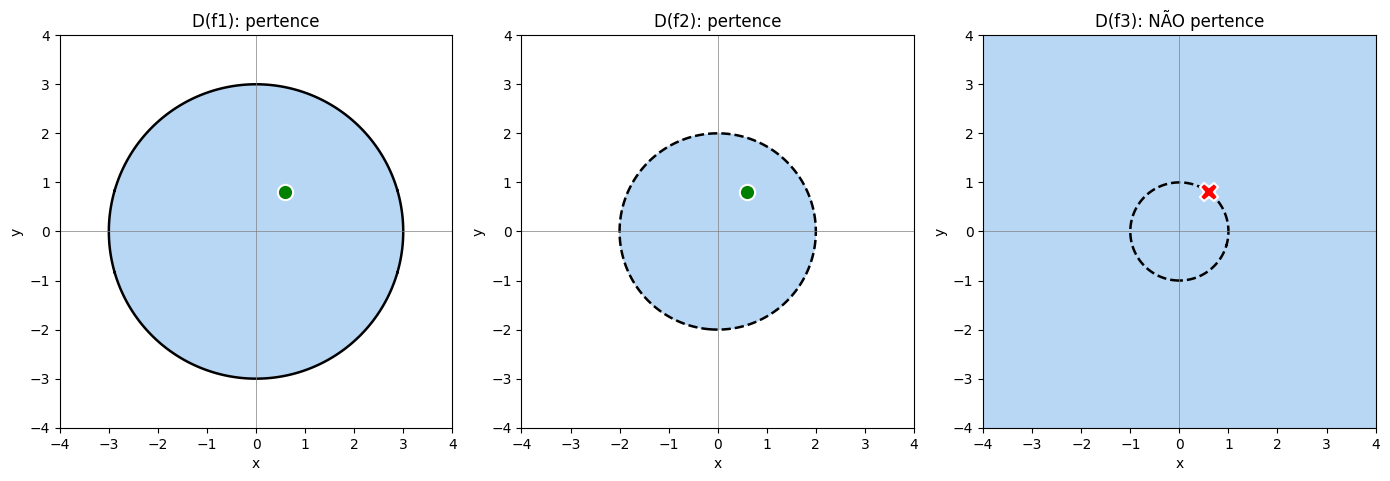

In [20]:
# 💻 Verificador interativo: digite a e b (aceita 3, -1.5, 1/2, sqrt(5), √5 ...) e clique em "Verificar"
caixa_a = widgets.Text(value='3', description='a =', layout=widgets.Layout(width='200px'))
caixa_b = widgets.Text(value='4', description='b =', layout=widgets.Layout(width='200px'))
botao = widgets.Button(description='Verificar', button_style='primary', icon='check')
exemplos = widgets.Dropdown(
    description='Exemplos:', layout=widgets.Layout(width='460px'),
    options=[('— escolha um exemplo —', None),
             ('(1, 1): dentro dos três domínios', ('1', '1')),
             ('(3, 4): fora de f₁ e de f₂', ('3', '4')),
             ('(3, 0): fronteira de f₁ (incluída)', ('3', '0')),
             ('(2, 0): fronteira de f₂ (excluída)', ('2', '0')),
             ('(1, 0): sobre o círculo unitário (f₃)', ('1', '0')),
             ('(√5, 2): fronteira EXATA de f₁ (decimais errariam)', ('sqrt(5)', '2')),
             ('(0.6, 0.8): círculo unitário digitado com decimais', ('0.6', '0.8'))])

display(widgets.VBox([widgets.HBox([caixa_a, caixa_b, botao]), exemplos]))

# Dois "painéis" com display_id: a cada verificação o conteúdo é SUBSTITUÍDO (update),
# em vez de acrescentado. Assim o resultado nunca se acumula/duplica.
painel_texto = display(Markdown('*verificando...*'), display_id=True)
painel_figura = display(Markdown(' '), display_id=True)


def ao_clicar(_=None):
    texto, fig = verificar_ponto(caixa_a.value, caixa_b.value)
    painel_texto.update(Markdown(texto))
    painel_figura.update(fig if fig is not None else Markdown(' '))


def ao_escolher_exemplo(mudanca):
    if mudanca['new'] is not None:
        caixa_a.value, caixa_b.value = mudanca['new']
        ao_clicar()


botao.on_click(ao_clicar)
exemplos.observe(ao_escolher_exemplo, names='value')
ao_clicar()